# Track 1 · Step 4: classification crops, label audit (300 crops), DataLoader

AI251P Capstone, Phase 1 (M1: *"label audit with an upper bound on the label-error rate"*, *"data loader with augmentation"*). Owner: Abdulmohsen Alharthi.

Input: `Processed/Splits/…_ClassCrops_vN.csv.gz` and `…_Splits_vN.json` from Step 3, and the image archives in `Raw/`.

1. **Crops**: every row of ClassCrops is cut from its image as a square around the box with `CROP_PAD` context on each side, resized to `STORE_SIZE`, and stored as one array per split (`.npy`, uint8) with an index CSV.
2. **Label audit**: a seeded, class-stratified sample of `AUDIT_N` = 300 crops (one per track or image), shown with more context and the box drawn. You fill in a verdict for each; section 7 turns it into a label-error rate per class and overall with a 95 % **upper bound**.
3. **DataLoader**: PyTorch dataset + augmentation (flips, 90° rotations, mild colour jitter, small random crop) and an optional class-balanced sampler. The same code is saved as `aerial_crops.py` for the repo.

Outputs (team naming rule `YYYY-MM-DD_Topic_vN`):
- `01_Data/Processed/Crops/…_Crops{Train,Val,Test}_vN.npy` and `…_CropIndex_vN.csv.gz`
- `01_Data/Processed/Crops/…_CropMontage_vN.png` (8 classes, for the dataset card)
- `01_Data/Processed/Audit/…_AuditSheet_vN.csv` and `…_AuditSheet_<class>_vN.png` (what you fill in)
- `01_Data/Processed/Audit/…_AuditResults_vN.csv` (after the audit)
- `01_Data/…_Step4Summary_vN.json`

Runtime: CPU is enough. Sections 1–6 cut ~94k crops (SeaDronesSee frames are large, so allow some minutes). Sections 7–9 can be re-run alone later in a new runtime, after the audit.

## 0. Settings

In [1]:
DRIVE_PROJECT = '/content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial'
DATA_DIR  = f'{DRIVE_PROJECT}/01_Data'
RAW_DIR   = f'{DATA_DIR}/Raw'
PROC_DIR  = f'{DATA_DIR}/Processed'
SPLIT_DIR, CROP_DIR, AUDIT_DIR = f'{PROC_DIR}/Splits', f'{PROC_DIR}/Crops', f'{PROC_DIR}/Audit'
LOCAL     = '/content/data'
SDS_LOCAL, UAVDT_LOCAL, CROP_LOCAL = f'{LOCAL}/seadronessee', f'{LOCAL}/uavdt', f'{LOCAL}/crops'
SEED = 42

CROP_PAD   = 0.15     # context on each side, as a fraction of the box's longer side (square crop)
STORE_SIZE = 96       # stored crop size in px; the model input size is chosen in Step 5 (IMG_SIZE below is for the check)
AUDIT_N        = 300  # crops in the label audit, stratified by class (equal number per class)
AUDIT_CONTEXT  = 3.0  # audit view shows 3x the box's longer side, box drawn in red
AUDIT_VIEW     = 160  # px per audit tile
IMG_SIZE, BATCH, BALANCE_POWER = 64, 128, 0.5   # DataLoader check only
N_WORKERS = 8

## 1. Mount Drive, find the Step 3 outputs

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, json, time, subprocess, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from concurrent.futures import ThreadPoolExecutor
for d in (CROP_DIR, AUDIT_DIR, CROP_LOCAL): os.makedirs(d, exist_ok=True)

TODAY = time.strftime('%Y-%m-%d')
_done = [int(m.group(1)) for f in os.listdir(DATA_DIR) if (m := re.match(rf'{TODAY}_Step4Summary_v(\d+)\.json$', f))]
VERSION = max(_done, default=0) + 1
def out_name(topic, ext): return f'{TODAY}_{topic}_v{VERSION}.{ext}'

def latest(folder, topic, ext, required=True):
    hits = []
    for f in os.listdir(folder):
        m = re.match(rf'(\d{{4}}-\d{{2}}-\d{{2}})_{topic}_v(\d+)\.{re.escape(ext)}$', f)
        if m: hits.append((m.group(1), int(m.group(2)), f))
    assert hits or not required, f'no {topic} file in {folder}'
    return f'{folder}/{max(hits)[2]}' if hits else None

IN = {'class_crops': latest(SPLIT_DIR, 'ClassCrops', 'csv.gz'), 'splits': latest(SPLIT_DIR, 'Splits', 'json')}
for k, v in IN.items(): print(f'{k:12s}', Path(v).name)
print('outputs of this run use version', VERSION)
SPLITS = ['train', 'val', 'test']
CLASSES = ['swimmer', 'boat', 'jetski', 'life_saving_appliances', 'buoy', 'car', 'truck', 'bus']
SUMMARY = {'seed': SEED, 'created': time.strftime('%Y-%m-%d %H:%M'), 'version': VERSION,
           'inputs': {k: Path(v).name for k, v in IN.items()},
           'settings': {'CROP_PAD': CROP_PAD, 'STORE_SIZE': STORE_SIZE, 'AUDIT_N': AUDIT_N, 'AUDIT_CONTEXT': AUDIT_CONTEXT}}

Mounted at /content/drive
class_crops  2026-10-19_ClassCrops_v1.csv.gz
splits       2026-10-19_Splits_v1.json
outputs of this run use version 1


## 2. Load the crop list and check it against the split file

In [ ]:
crops = pd.read_csv(IN['class_crops'], keep_default_na=False, dtype={'ann_id': str, 'track': str})
crops['crop_id'] = np.arange(len(crops))
SP = json.load(open(IN['splits']))
v2s, s2s = SP['seadronessee']['video_to_split'], SP['uavdt']['seq_to_split']
expect = np.where(crops.dataset == 'SeaDronesSee', crops.source.map(v2s), crops.source.map(s2s))
assert (expect == crops.split).all(), f'{(expect != crops.split).sum()} crops disagree with the split file'
assert set(crops.category) <= set(CLASSES), set(crops.category) - set(CLASSES)
crops['box_side'] = crops[['w', 'h']].max(axis=1)
crops['size_bin'] = pd.cut(crops.box_side, [0, 16, 32, 64, 1e9], labels=['<16', '16-32', '32-64', '>64'], right=False)
print(len(crops), 'crops, UAVDT grouping:', SP['uavdt']['grouping'])
display(crops.pivot_table(index='category', columns='split', values='crop_id', aggfunc='size', fill_value=0).reindex(CLASSES)[SPLITS])
display(pd.crosstab(crops.category, crops.size_bin).reindex(CLASSES))

94276 crops, UAVDT grouping: sequence


split,train,val,test
category,,,
swimmer,32238,6093,4955
boat,9707,2319,3206
jetski,1793,443,414
life_saving_appliances,856,213,184
buoy,3476,659,810
car,15969,3383,3388
truck,1807,398,345
bus,1079,292,249


size_bin,<16,16-32,32-64,>64
category,,,,
swimmer,1487,14389,18859,8551
boat,2,481,2153,12596
jetski,6,137,575,1932
life_saving_appliances,53,488,706,6
buoy,174,1296,1312,2163
car,2646,7572,9573,2949
truck,33,526,1212,779
bus,11,216,541,852


## 3. Extract the image archives (skipped if already done in this runtime)

SeaDronesSee: every archive in `Raw/SeaDronesSee`. UAVDT: only the image archive `UAV-benchmark-M*.zip` (the GT and attribute archives are not needed here).

In [ ]:
def sh(cmd):
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if r.returncode != 0: print(r.stderr[-2000:]); raise RuntimeError(cmd)

def extract(archive, dest):
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    marker = dest / f'.extracted_{Path(archive).name}.done'
    if marker.exists(): return
    print('extracting', Path(archive).name); sh(f'unzip -q -o "{archive}" -d "{dest}"'); marker.touch()

for z in sorted(Path(RAW_DIR, 'SeaDronesSee').glob('*.zip')): extract(z, SDS_LOCAL)
for z in sorted(Path(SDS_LOCAL).rglob('*.zip')): extract(z, z.parent)
uav_zips = sorted(Path(RAW_DIR, 'UAVDT').glob('UAV-benchmark-M*.zip'))
uav_zips = [z for z in uav_zips if 'MOTD' not in z.name]
assert uav_zips, 'UAV-benchmark-M.zip not found in Raw/UAVDT'
for z in uav_zips: extract(z, UAVDT_LOCAL)

sds_files = {p.name: str(p) for p in Path(SDS_LOCAL).rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}}
seq_dirs = {p.name: p for p in Path(UAVDT_LOCAL).rglob('M[0-9][0-9][0-9][0-9]') if p.is_dir()}
crops['path'] = np.where(crops.dataset == 'SeaDronesSee', crops.image.map(lambda f: sds_files.get(Path(f).name, '')),
                         crops.image.map(lambda f: str(seq_dirs[f.split('/')[0]] / f.split('/')[1]) if f.split('/')[0] in seq_dirs else ''))
missing = crops[(crops.path == '') | ~crops.path.map(os.path.exists)]
print('crops whose image is missing:', len(missing))
assert len(missing) == 0, missing.head()

extracting SeaDronesSee_ODv2_CompressedVersion.zip
extracting UAV-benchmark-M.zip
crops whose image is missing: 0


## 4. Cut the crops

Square around the box centre, side = longer box side × (1 + 2 × `CROP_PAD`), resized to `STORE_SIZE` (bicubic). Context outside the image is filled with black. Each image is opened once for all its boxes.

In [ ]:
def square(img, x, y, w, h, pad, out):
    cx, cy, s = x + w / 2, y + h / 2, max(w, h) * (1 + 2 * pad)
    return img.crop((round(cx - s / 2), round(cy - s / 2), round(cx + s / 2), round(cy + s / 2))).resize((out, out), Image.BICUBIC)

crops['row'] = crops.groupby('split').cumcount()
ARR = {s: np.lib.format.open_memmap(f'{CROP_LOCAL}/{s}.npy', mode='w+', dtype=np.uint8,
                                    shape=(int((crops.split == s).sum()), STORE_SIZE, STORE_SIZE, 3)) for s in SPLITS}
def cut_image(item):
    path, g = item
    try:
        with Image.open(path) as im:
            im = im.convert('RGB')
            for r in g.itertuples():
                ARR[r.split][r.row] = np.asarray(square(im, r.x, r.y, r.w, r.h, CROP_PAD, STORE_SIZE))
        return None
    except Exception as e:
        return (path, repr(e))

t0 = time.time(); groups = list(crops.groupby('path')); errors = []
with ThreadPoolExecutor(N_WORKERS) as ex:
    for i, err in enumerate(ex.map(cut_image, groups)):
        if err: errors.append(err)
        if (i + 1) % 2000 == 0: print(f'{i + 1}/{len(groups)} images, {time.time() - t0:.0f}s')
for a in ARR.values(): a.flush()
print(f'{len(groups)} images, {len(crops)} crops in {time.time() - t0:.0f}s, errors: {len(errors)}')
assert not errors, errors[:5]

2000/16582 images, 54s
4000/16582 images, 101s
6000/16582 images, 179s
8000/16582 images, 231s
10000/16582 images, 289s
12000/16582 images, 310s
14000/16582 images, 321s
16000/16582 images, 331s
16582 images, 94276 crops in 335s, errors: 0


## 5. Save the crops to Drive, montage for the dataset card

saved 2026-10-20_CropsTrain_v1.npy (66925, 96, 96, 3)
saved 2026-10-20_CropsVal_v1.npy (13800, 96, 96, 3)
saved 2026-10-20_CropsTest_v1.npy (13551, 96, 96, 3)


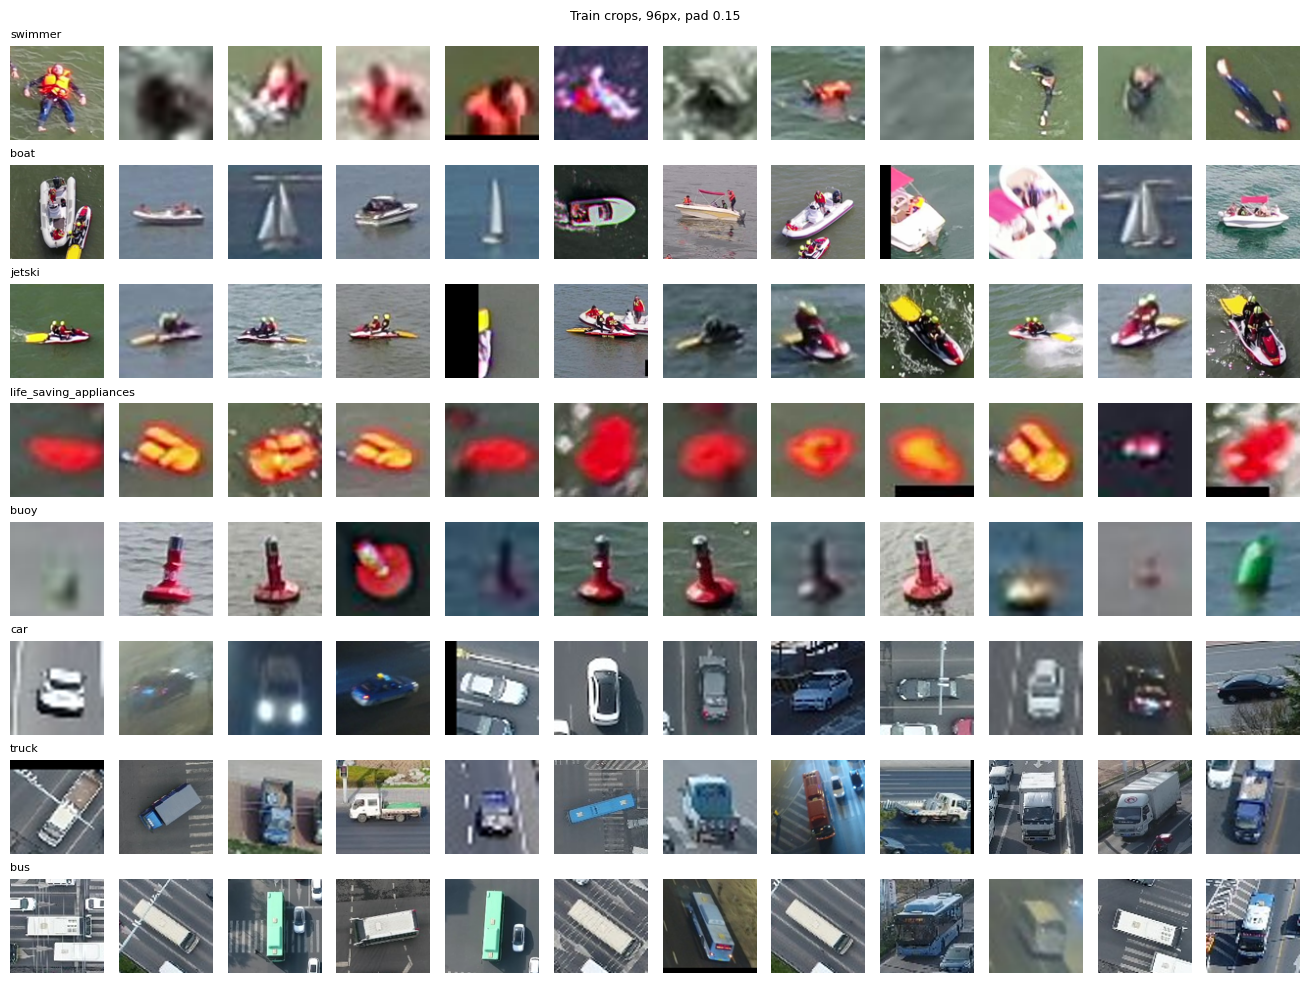

In [ ]:
for s in SPLITS:
    dst = f'{CROP_DIR}/{out_name("Crops" + s.capitalize(), "npy")}'
    shutil.copy(f'{CROP_LOCAL}/{s}.npy', dst); print('saved', Path(dst).name, ARR[s].shape)
index_cols = ['crop_id', 'split', 'row', 'dataset', 'category', 'image', 'x', 'y', 'w', 'h', 'box_side', 'size_bin',
              'group', 'source', 'track', 'ann_id', 'label_changed']
crops[index_cols].to_csv(f'{CROP_DIR}/{out_name("CropIndex", "csv.gz")}', index=False)

rng = np.random.default_rng(SEED); K = 12
fig, axes = plt.subplots(len(CLASSES), K, figsize=(K * 1.1, len(CLASSES) * 1.25))
for i, c in enumerate(CLASSES):
    sub = crops[(crops.category == c) & (crops.split == 'train')]
    pick = sub.iloc[rng.choice(len(sub), min(K, len(sub)), replace=False)] if len(sub) else sub
    for j in range(K):
        ax = axes[i, j]; ax.axis('off')
        if j < len(pick): r = pick.iloc[j]; ax.imshow(ARR[r.split][r.row])
        if j == 0: ax.set_title(c, fontsize=8, loc='left')
plt.suptitle(f'Train crops, {STORE_SIZE}px, pad {CROP_PAD}', fontsize=9); plt.tight_layout()
plt.savefig(f'{CROP_DIR}/{out_name("CropMontage", "png")}', dpi=120); plt.show()
SUMMARY['crops'] = {'per_split': crops.split.value_counts().to_dict(),
                    'per_class_split': crops.pivot_table(index='category', columns='split', values='crop_id',
                                                         aggfunc='size', fill_value=0).to_dict(orient='index'),
                    'size_bins': pd.crosstab(crops.category, crops.size_bin).to_dict(orient='index'),
                    'array_bytes': int(sum(a.nbytes for a in ARR.values()))}

## 6. Label audit: draw the sample and the sheets

`AUDIT_N` crops, the same number per class (300 / 8 → 37 or 38), seeded, from all three splits. At most one crop per UAVDT track (so no vehicle is judged twice), and spread over videos and sequences: one crop from each source first, then a second from each, and so on.

**How to fill it in** (open the CSV in Google Sheets next to the PNG sheets; tiles are numbered by `audit_id`):

| `verdict` | meaning |
|---|---|
| `ok` | the box shows one object of the given class |
| `wrong_class` | an object, but another class: put it in `true_label` |
| `not_object` | background, a reflection, a wave, nothing |
| `bad_box` | right class, but the box is badly off (cuts most of the object or covers two) |
| `unsure` | cannot tell at this resolution |

Save the filled sheet as CSV into `01_Data/Processed/Audit/` named `YYYY-MM-DD_AuditFilled_v1.csv` (keep every column). If a second member also audits, add a column `verdict_2`: section 7 then reports agreement too.

In [ ]:
rng = np.random.default_rng(SEED)
# one crop per UAVDT track; then spread over sources: first one crop from every video/sequence, then a second, ...
pool = crops[(crops.dataset == 'SeaDronesSee') | ~crops.duplicated('track')]
pool = pool.sample(frac=1, random_state=SEED)
pool = pool.assign(rank=pool.groupby(['category', 'source']).cumcount()).sort_values('rank', kind='stable')
per = [AUDIT_N // len(CLASSES) + (i < AUDIT_N % len(CLASSES)) for i in range(len(CLASSES))]
audit = pd.concat([pool[pool.category == c].head(k) for c, k in zip(CLASSES, per)]).drop(columns='rank').reset_index(drop=True)
audit.insert(0, 'audit_id', [f'A{i:03d}' for i in range(1, len(audit) + 1)])
for col in ('verdict', 'true_label', 'note'): audit[col] = ''

def audit_view(r):
    with Image.open(r.path) as im:
        im = im.convert('RGB')
        cx, cy, s = r.x + r.w / 2, r.y + r.h / 2, max(r.w, r.h) * AUDIT_CONTEXT
        x0, y0 = cx - s / 2, cy - s / 2
        v = im.crop((round(x0), round(y0), round(x0 + s), round(y0 + s))).resize((AUDIT_VIEW, AUDIT_VIEW), Image.BICUBIC)
    k = AUDIT_VIEW / s; d = ImageDraw.Draw(v)
    d.rectangle([(r.x - x0) * k - 1, (r.y - y0) * k - 1, (r.x + r.w - x0) * k + 1, (r.y + r.h - y0) * k + 1], outline=(255, 0, 0), width=2)
    return v

COLS = 8
for c in CLASSES:
    sub = audit[audit.category == c]
    if not len(sub): continue
    rows_n = int(np.ceil(len(sub) / COLS))
    fig, axes = plt.subplots(rows_n, COLS, figsize=(COLS * 2, rows_n * 2.2)); axes = np.atleast_2d(axes)
    for ax in axes.flat: ax.axis('off')
    for ax, r in zip(axes.flat, sub.itertuples()):
        ax.imshow(audit_view(r)); ax.set_title(f'{r.audit_id} {r.dataset[:3]} {int(r.box_side)}px', fontsize=8)
    plt.suptitle(f'Label audit: labelled "{c}" (red box = the labelled object)', fontsize=10); plt.tight_layout()
    plt.savefig(f'{AUDIT_DIR}/{out_name("AuditSheet_" + c, "png")}', dpi=100); plt.close(fig)
sheet_cols = ['audit_id', 'category', 'verdict', 'true_label', 'note', 'dataset', 'split', 'image', 'x', 'y', 'w', 'h',
              'box_side', 'source', 'track', 'ann_id', 'crop_id', 'label_changed']
audit[sheet_cols].to_csv(f'{AUDIT_DIR}/{out_name("AuditSheet", "csv")}', index=False)
print('audit sample per class:', audit.category.value_counts().reindex(CLASSES).to_dict())
print('per split:', audit.split.value_counts().to_dict(), '| sheets in', AUDIT_DIR)
SUMMARY['audit_sample'] = {'n': len(audit), 'per_class': audit.category.value_counts().to_dict(),
                           'per_split': audit.split.value_counts().to_dict(), 'sheet': out_name('AuditSheet', 'csv')}

audit sample per class: {'swimmer': 38, 'boat': 38, 'jetski': 38, 'life_saving_appliances': 38, 'buoy': 37, 'car': 37, 'truck': 37, 'bus': 37}
per split: {'train': 212, 'val': 46, 'test': 42} | sheets in /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial/01_Data/Processed/Audit


## 7. Label audit results (run after the sheet is filled)

- **Label error** = `wrong_class` or `not_object`. `bad_box` is reported separately (box quality, not class). `unsure` is left out of the rate, and a worst case counts it as an error.
- **Per class**: error rate with a one-sided 95 % Clopper–Pearson upper bound (with 0 errors in n, this is about 3/n).
- **Overall**: the sample has the same number per class, but the data does not, so the overall rate weights each class by its share of all crops. Its 95 % upper bound comes from a stratified bootstrap (seeded, 10,000 draws).

In [3]:
from scipy.stats import beta
FILLED = latest(AUDIT_DIR, 'AuditFilled', 'csv', required=False)
if FILLED is None:
    print('No *_AuditFilled_vN.csv yet in', AUDIT_DIR, '-> fill in the audit sheet, then run sections 7-9.')
else:
    af = pd.read_csv(FILLED, keep_default_na=False)
    af['verdict'] = af.verdict.str.strip().str.lower()
    bad_v = set(af.verdict) - {'ok', 'wrong_class', 'not_object', 'bad_box', 'unsure'}
    assert not bad_v, f'unknown verdicts: {bad_v} (or empty rows)'
    assert ((af.verdict != 'wrong_class') | af.true_label.isin(CLASSES)).all(), 'wrong_class rows need a true_label from CLASSES'
    af['error'] = af.verdict.isin(['wrong_class', 'not_object'])

    def cp_upper(k, n, a=0.05): return 1.0 if n == 0 else (1.0 if k == n else float(beta.ppf(1 - a, k + 1, n - k)))
    rows = []
    for c in CLASSES:
        g = af[af.category == c]; j = g[g.verdict != 'unsure']
        k, n = int(j.error.sum()), len(j)
        rows.append({'class': c, 'audited': len(g), 'judged': n, 'errors': k, 'bad_box': int((g.verdict == 'bad_box').sum()),
                     'unsure': int((g.verdict == 'unsure').sum()), 'error_rate': k / n if n else np.nan,
                     'upper95': cp_upper(k, n), 'upper95_unsure_as_error': cp_upper(k + int((g.verdict == 'unsure').sum()), len(g))})
    res = pd.DataFrame(rows).set_index('class')
    share = crops.category.value_counts(normalize=True).reindex(CLASSES).fillna(0) if 'crops' in globals() else \
            pd.read_csv(latest(CROP_DIR, 'CropIndex', 'csv.gz')).category.value_counts(normalize=True).reindex(CLASSES).fillna(0)
    res['share_of_all_crops'] = share
    overall = float((res.error_rate.fillna(0) * share).sum())
    rng = np.random.default_rng(SEED); boots = np.zeros(10_000)
    for c in CLASSES:
        e = af[(af.category == c) & (af.verdict != 'unsure')].error.to_numpy()
        if len(e): boots += share[c] * rng.binomial(len(e), e.mean() if e.mean() > 0 else 0, 10_000) / len(e)
    # a class with 0 observed errors gets no bootstrap spread, so also add its Clopper-Pearson bound as a floor
    floor = float((res.upper95 * share).sum())
    res.loc['overall (weighted)'] = {'audited': len(af), 'judged': int((af.verdict != 'unsure').sum()), 'errors': int(af.error.sum()),
                                     'bad_box': int((af.verdict == 'bad_box').sum()), 'unsure': int((af.verdict == 'unsure').sum()),
                                     'error_rate': overall, 'upper95': float(np.quantile(boots, 0.95)),
                                     'upper95_unsure_as_error': np.nan, 'share_of_all_crops': 1.0}
    display(res.round(4))
    print(f'overall label-error rate {overall:.2%}, 95% upper bound (bootstrap) {res.loc["overall (weighted)", "upper95"]:.2%}; '
          f'conservative bound (weighted per-class Clopper-Pearson) {floor:.2%}')
    wrong = af[af.verdict == 'wrong_class']
    if len(wrong): print('wrong_class pairs (given -> true):'); display(pd.crosstab(wrong.category, wrong.true_label))
    res.to_csv(f'{AUDIT_DIR}/{out_name("AuditResults", "csv")}')
    SUMMARY['audit_results'] = {'file': Path(FILLED).name, 'overall_rate': overall,
                                'overall_upper95_bootstrap': float(res.loc['overall (weighted)', 'upper95']),
                                'overall_upper95_conservative': floor,
                                'per_class': res.drop(index='overall (weighted)').to_dict(orient='index')}
    if 'verdict_2' in af and (af.verdict_2.astype(str).str.strip() != '').all():
        v2 = af.verdict_2.astype(str).str.strip().str.lower()
        po = float((v2 == af.verdict).mean())
        pe = float(sum(af.verdict.value_counts(normalize=True).get(k, 0) * v2.value_counts(normalize=True).get(k, 0)
                       for k in set(af.verdict) | set(v2)))
        SUMMARY['audit_results']['agreement'] = {'raw': po, 'cohen_kappa': (po - pe) / (1 - pe) if pe < 1 else 1.0}
        print('two-reviewer agreement:', SUMMARY['audit_results']['agreement'])

/tmp/ipykernel_745/1060705066.py:23: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  pd.read_csv(latest(CROP_DIR, 'CropIndex', 'csv.gz')).category.value_counts(normalize=True).reindex(CLASSES).fillna(0)


,audited,judged,errors,bad_box,unsure,error_rate,upper95,upper95_unsure_as_error,share_of_all_crops
class,,,,,,,,,
swimmer,38,29,2,3,9,0.069,0.2016,0.4333,0.4591
boat,38,37,0,8,1,0.000,0.0778,0.1189,0.1616
jetski,38,31,0,1,7,0.000,0.0921,0.3183,0.0281
life_saving_appliances,38,24,0,0,14,0.000,0.1173,0.5147,0.0133
buoy,37,27,0,2,10,0.000,0.1050,0.4152,0.0525
car,37,27,1,4,10,0.037,0.1640,0.4438,0.2412
truck,37,32,4,0,5,0.125,0.2636,0.3861,0.0270
bus,37,34,0,0,3,0.000,0.0843,0.1964,0.0172
overall (weighted),300,241,7,18,59,0.044,0.0854,NaN,1.0000


overall label-error rate 4.40%, 95% upper bound (bootstrap) 8.54%; conservative bound (weighted per-class Clopper-Pearson) 16.29%
wrong_class pairs (given -> true):


true_label,bus,car
category,,
car,1,0
truck,1,3


## 8. DataLoader with augmentation

The cell below writes `aerial_crops.py` (the same file is in the Track 1 folder for the repo) and imports it.

- **Train augmentation**: random crop 75–100 % of the area (aspect 0.9–1.1) resized to `IMG_SIZE`, horizontal flip, random 90° rotation (aerial views have no fixed "up"), mild colour jitter. No vertical flip on top of that: flip + 90° rotations already give all 8 orientations.
- **Val / test**: resize only.
- **Imbalance**: optional `WeightedRandomSampler` with weight ∝ 1 / n_c^`BALANCE_POWER` (0.5 = square root, between none and full balance). `class_weights()` gives the same numbers for a weighted loss. Step 5 decides which one to use.
- **Reproducible**: seeded generator and `seed_worker` for the workers.

In [4]:
%%writefile /content/aerial_crops.py
"""Aerial object crops for the AI251P 8-class classifier (Track 1).

Crops are stored by Step 4 as one uint8 array per split, shape (N, S, S, 3), plus an index CSV whose
`row` column points into the array. Labels follow CLASSES below.
"""
import numpy as np, pandas as pd, torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.transforms import v2 as T

CLASSES = ['swimmer', 'boat', 'jetski', 'life_saving_appliances', 'buoy', 'car', 'truck', 'bus']
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet, used for scratch and pretrained alike


class Rot90:
    """Random multiple of 90 degrees: aerial views have no fixed 'up'."""
    def __call__(self, x):
        return torch.rot90(x, int(torch.randint(4, (1,))), dims=(-2, -1))


def make_transforms(img_size, train):
    if train:
        return T.Compose([T.ToImage(), T.RandomResizedCrop(img_size, scale=(0.75, 1.0), ratio=(0.9, 1.1), antialias=True),
                          T.RandomHorizontalFlip(), Rot90(),
                          T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
                          T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])
    return T.Compose([T.ToImage(), T.Resize(img_size, antialias=True),
                      T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])


class CropDataset(Dataset):
    def __init__(self, array_path, index, transform=None):
        self.x = np.load(array_path, mmap_mode='r')
        self.index = index.sort_values('row').reset_index(drop=True)
        self.y = self.index.category.map(CLASS_TO_ID).to_numpy()
        assert len(self.index) == len(self.x) and not np.isnan(self.y.astype(float)).any()
        self.transform = transform

    def __len__(self): return len(self.index)

    def __getitem__(self, i):
        img = np.array(self.x[i])          # copy out of the read-only memmap
        if self.transform is not None: img = self.transform(img)
        return img, int(self.y[i])


def class_weights(labels, power=0.5):
    """w_c proportional to 1 / n_c**power, mean weight over samples = 1. power 0 = none, 1 = full balance."""
    n = np.bincount(labels, minlength=len(CLASSES)).astype(float)
    w = np.where(n > 0, 1.0 / np.maximum(n, 1) ** power, 0.0)
    return w / (w[labels].mean())


def seed_worker(worker_id):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s); import random; random.seed(s)


def make_loader(ds, batch_size, train, seed=42, balance_power=0.5, num_workers=2):
    g = torch.Generator().manual_seed(seed)
    sampler = None
    if train and balance_power > 0:
        w = class_weights(ds.y, balance_power)[ds.y]
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(ds), replacement=True, generator=g)
    return DataLoader(ds, batch_size=batch_size, shuffle=train and sampler is None, sampler=sampler,
                      num_workers=num_workers, worker_init_fn=seed_worker, generator=g,
                      pin_memory=torch.cuda.is_available(), drop_last=train, persistent_workers=num_workers > 0)

Writing /content/aerial_crops.py


batch (128, 3, 64, 64) torch.float32 | mean 0.038 std 0.954


,data,sampled
swimmer,48.2,29.5
boat,14.5,16.1
jetski,2.7,6.9
life_saving_appliances,1.3,4.8
buoy,5.2,9.5
car,23.9,20.7
truck,2.7,7.0
bus,1.6,5.4


loss class weights: {'swimmer': 0.611, 'boat': 1.113, 'jetski': 2.589, 'life_saving_appliances': 3.748, 'buoy': 1.86, 'car': 0.868, 'truck': 2.579, 'bus': 3.338}


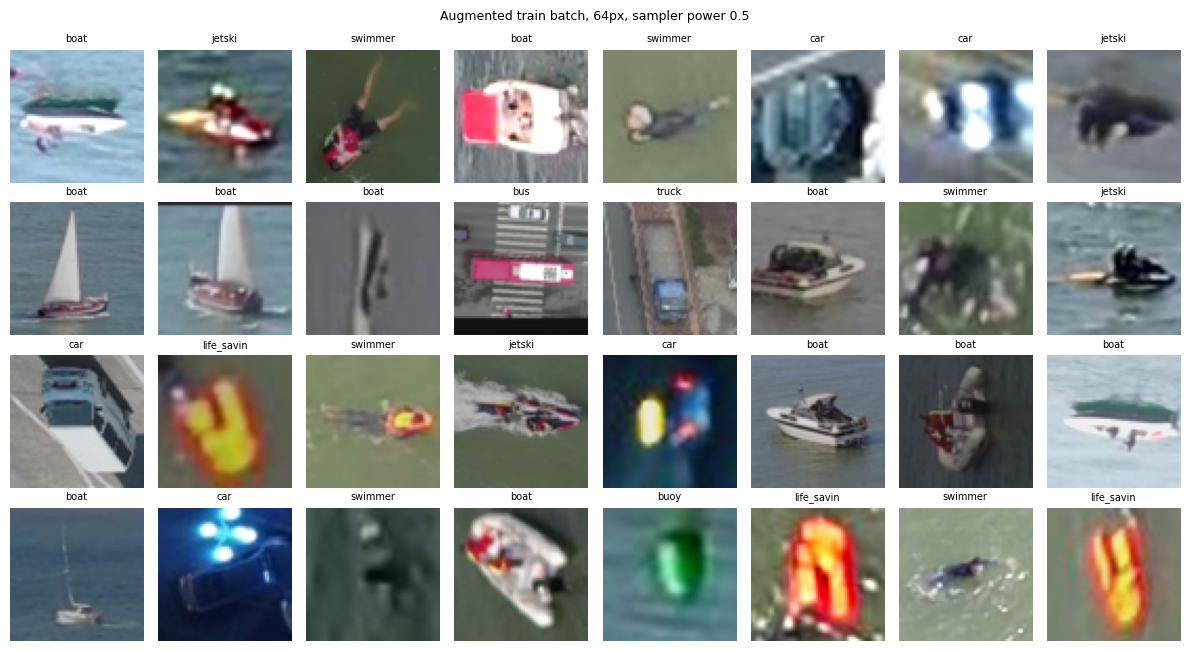

loader speed: 693 crops/s (50 batches, 2 workers)


In [ ]:
!pip -q install torch torchvision 2>/dev/null
import sys, importlib; sys.path.insert(0, '/content')
import torch, aerial_crops as ac; importlib.reload(ac)
assert ac.CLASSES == CLASSES
src = {s: f'{CROP_LOCAL}/{s}.npy' if os.path.exists(f'{CROP_LOCAL}/{s}.npy') else latest(CROP_DIR, 'Crops' + s.capitalize(), 'npy') for s in SPLITS}
index = crops if 'crops' in globals() and 'row' in crops else pd.read_csv(latest(CROP_DIR, 'CropIndex', 'csv.gz'), keep_default_na=False)
DS = {s: ac.CropDataset(src[s], index[index.split == s], ac.make_transforms(IMG_SIZE, train=(s == 'train'))) for s in SPLITS}
train_dl = ac.make_loader(DS['train'], BATCH, train=True, seed=SEED, balance_power=BALANCE_POWER, num_workers=2)
x, y = next(iter(train_dl)); print('batch', tuple(x.shape), x.dtype, '| mean', x.mean().item().__round__(3), 'std', x.std().item().__round__(3))

# what the sampler does to the class mix (labels only, no images decoded)
w = ac.class_weights(DS['train'].y, BALANCE_POWER)[DS['train'].y]
drawn = np.random.default_rng(SEED).choice(len(w), 200 * BATCH, p=w / w.sum())
mix = pd.DataFrame({'data': pd.Series(DS['train'].y).map(dict(enumerate(CLASSES))).value_counts(normalize=True),
                    'sampled': pd.Series(DS['train'].y[drawn]).map(dict(enumerate(CLASSES))).value_counts(normalize=True)}).reindex(CLASSES)
display((mix * 100).round(1))
cw = pd.Series(ac.class_weights(DS['train'].y, BALANCE_POWER), index=CLASSES); print('loss class weights:', cw.round(3).to_dict())

m, s_ = torch.tensor(ac.MEAN)[:, None, None], torch.tensor(ac.STD)[:, None, None]
fig, axes = plt.subplots(4, 8, figsize=(12, 6.6))
for ax, im, lab in zip(axes.flat, x[:32], y[:32]):
    ax.imshow((im * s_ + m).clamp(0, 1).permute(1, 2, 0)); ax.set_title(CLASSES[lab][:10], fontsize=7); ax.axis('off')
plt.suptitle(f'Augmented train batch, {IMG_SIZE}px, sampler power {BALANCE_POWER}', fontsize=9); plt.tight_layout()
plt.savefig(f'{CROP_DIR}/{out_name("AugmentedBatch", "png")}', dpi=110); plt.show()

t0 = time.time(); n = 0
for i, (xb, yb) in enumerate(train_dl):
    n += len(xb)
    if i == 49: break
print(f'loader speed: {n / (time.time() - t0):.0f} crops/s (50 batches, 2 workers)')
SUMMARY['loader'] = {'IMG_SIZE': IMG_SIZE, 'BATCH': BATCH, 'BALANCE_POWER': BALANCE_POWER, 'sizes': {s: len(d) for s, d in DS.items()},
                     'sampled_mix_%': (mix.sampled * 100).round(2).to_dict(), 'loss_class_weights': cw.round(4).to_dict(),
                     'train_aug': 'RandomResizedCrop(0.75-1, ratio 0.9-1.1), HFlip, Rot90, ColorJitter(0.3,0.3,0.2,0.02)'}

## 9. Summary

In [5]:
def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, (np.floating, float)): return None if o != o else float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
out = f'{DATA_DIR}/{out_name("Step4Summary", "json")}'
json.dump(jsonable(SUMMARY), open(out, 'w'), indent=2, ensure_ascii=False)
print('saved', out); print(json.dumps(jsonable(SUMMARY), indent=1)[:4000])

saved /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial/01_Data/2026-10-21_Step4Summary_v1.json
{
 "seed": 42,
 "created": "2026-10-21 15:28",
 "version": 1,
 "inputs": {
  "class_crops": "2026-10-19_ClassCrops_v1.csv.gz",
  "splits": "2026-10-19_Splits_v1.json"
 },
 "settings": {
  "CROP_PAD": 0.15,
  "STORE_SIZE": 96,
  "AUDIT_N": 300,
  "AUDIT_CONTEXT": 3.0
 },
 "audit_results": {
  "file": "2026-10-21_AuditFilled_v1.csv",
  "overall_rate": 0.043979523967208695,
  "overall_upper95_bootstrap": 0.08542327530935905,
  "overall_upper95_conservative": 0.16289885416422212,
  "per_class": {
   "swimmer": {
    "audited": 38,
    "judged": 29,
    "errors": 2,
    "bad_box": 3,
    "unsure": 9,
    "error_rate": 0.06896551724137931,
    "upper95": 0.20156058792150391,
    "upper95_unsure_as_error": 0.4333388431838118,
    "share_of_all_crops": 0.4591412448555306
   },
   "boat": {
    "audited": 38,
    "judged": 37,
    "errors": 0,
    "bad_box": 8,
    "unsure": 1,
    "error_rate